# Bias and variance in polynomial regression

We will study how the degree of a polynomial affects its predictions when the training data change.

Our true function is
$$
f(x)=0.5x+2x^2+2.
$$
Each observation contains measurement noise:
$$
y_i=f(x_i)+\epsilon_i,\qquad
\epsilon_i\sim\mathcal{N}(0,\sigma_\epsilon^2).
$$
The inputs are sampled independently and uniformly from $[-1,1]$. The noise terms are independent of the inputs and of one another. We use $n=50$ observations per training set and $\sigma_\epsilon=0.5$.

First, we study predictions at one fixed input, $x_{\mathrm{test}}=1.2$. This tests generalization by **extrapolation**, because the test input is outside the training interval. The true response there is $f(x_{\mathrm{test}})$; a noisy test observation is $y_{\mathrm{test}}=f(x_{\mathrm{test}})+\epsilon_{\mathrm{test}}$, with independent noise.

Later, we will use 100 observations per training set and noise standard deviation 1, and average errors over test inputs sampled from $[0.5,1.5)$. Some of those test inputs also require extrapolation.

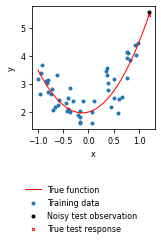

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Use 8-point text everywhere in the plots.
fntsz = 8
plt.rcParams.update({
    'font.size': fntsz,
    'axes.titlesize': fntsz,
    'axes.labelsize': fntsz,
    'xtick.labelsize': fntsz,
    'ytick.labelsize': fntsz,
    'legend.fontsize': fntsz,
    'legend.title_fontsize': fntsz,
    'figure.titlesize': fntsz,
    'lines.linewidth': 1,
    'lines.markersize': 3,
})

# US Letter is 8.5 inches wide: each plotting area is 1.7 inches wide.
panel_width = 8.5 / 5
panel_height = panel_width

# Keep this formatting helper separate from the regression calculations.
def plot_panels(nrows=1, ncols=1, sharex=False, sharey=False):
    # Add space for labels, titles, gaps, and a legend below the panels.
    fig_width = ncols * panel_width + 0.7 + (ncols - 1) * 0.55
    fig_height = nrows * panel_height + 2.15 + (nrows - 1) * 0.9
    fig, axs = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height),
                            sharex=sharex, sharey=sharey)
    # Fixed margins preserve the physical width of each plotting area.
    fig.subplots_adjust(
        left=0.5 / fig_width, right=1 - 0.2 / fig_width,
        bottom=1.5 / fig_height, top=1 - 0.65 / fig_height,
        wspace=0.55 / panel_width, hspace=0.9 / panel_height,
    )
    return fig, axs


# Make the random examples repeatable when we run from the top.
np.random.seed(1)

# Define the true function that generates the data.
def f(x):
    return 0.5 * x + 2*x**2 + 2

n = 50                 # Number of observations in each training set.
x_max = 1              # Training inputs lie between -1 and 1.
sigma_epsilon = 0.5    # Standard deviation of the measurement noise.

# Generate one training set.
x_train = np.random.uniform(-x_max, x_max, n)
noise = np.random.normal(0, sigma_epsilon, n)
y_train = f(x_train) + noise

# Generate an independent noisy observation at the test input.
x_test = 1.2
y_true = f(x_test)
y_test = y_true + np.random.normal(0, sigma_epsilon)

# Use a smooth grid to draw curves, including the test input.
x_plot = np.linspace(-x_max, x_test, 200)

fig, ax = plot_panels()
plt.plot(x_plot, f(x_plot), color='red', label='True function')
plt.scatter(x_train, y_train, label='Training data')
plt.scatter(x_test, y_test, color='black', label='Noisy test observation')
plt.scatter(x_test, y_true, color='red', marker='x', label='True test response')
plt.xlabel('x')
plt.ylabel('y')
fig.legend(loc='lower center', frameon=False)
plt.show()


## Fit polynomials to several training sets

For degree $d$, our model is
$$
\hat f_{d,D}(x)=w_0+w_1x+\cdots+w_dx^d.
$$
There are $d+1$ coefficients, including the intercept $w_0$. The subscript $D$ reminds us that the fitted coefficients depend on the training dataset.

We choose the coefficients by minimizing the sum of squared training errors. Under our independent Gaussian noise model with a common variance, this is also maximum likelihood estimation.

We use `np.polyfit(x_train, y_train, d)` to fit a polynomial. It returns coefficients in the order $[w_d,\ldots,w_1,w_0]$. We use `np.polyval(w, x)` to evaluate that polynomial.

We compare degrees $d=0,1,2,3,4,5$. Each of six experiments uses a fresh training set of 50 observations. Within an experiment, all degrees use the same training set so that their predictions are easy to compare.

The first figure compares degrees within each experiment. The second compares fitted curves across experiments for each degree. Six experiments illustrate variability; later we will use more experiments to estimate bias and variance.


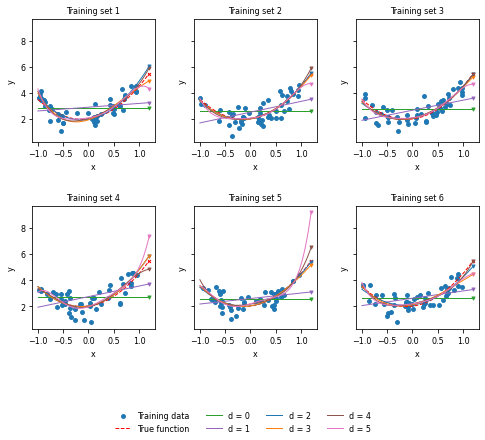

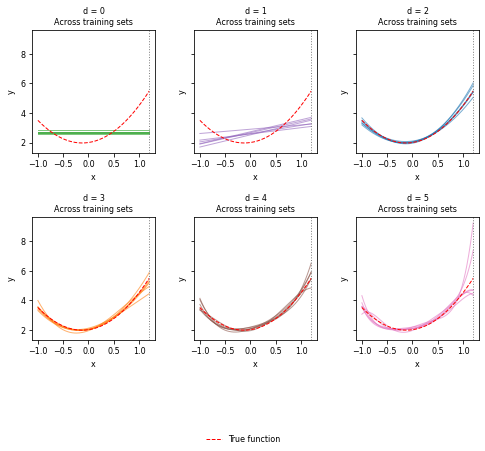

In [3]:
d_arr = [0, 1, 2, 3, 4, 5]
colors = ['tab:green', 'tab:purple', 'tab:blue', 'tab:orange', 'tab:brown', 'tab:pink']
n_examples = 6
all_weights = []       # Each entry will contain the six fits for one dataset.

fig, axs = plot_panels(2, 3, sharey=True)

for r in range(n_examples):
    # Generate a fresh training set for this experiment.
    x_train = np.random.uniform(-x_max, x_max, n)
    y_train = f(x_train) + np.random.normal(0, sigma_epsilon, n)

    # Select the next panel, reading the panels in row order.
    ax = axs.flat[r]
    ax.scatter(x_train, y_train, s=15, label='Training data')
    ax.plot(x_plot, f(x_plot), 'r--', label='True function')
    ax.scatter(x_test, y_true, color='red', marker='x')

    weights = []
    for k in range(len(d_arr)):
        d = d_arr[k]
        w = np.polyfit(x_train, y_train, d)   # Fit degree d to this dataset.
        weights.append(w)                   # Save the coefficients.
        y_fit = np.polyval(w, x_plot)        # Evaluate the fitted curve.
        prediction = np.polyval(w, x_test)   # Predict at the test input.
        ax.plot(x_plot, y_fit, color=colors[k], label=f'd = {d}')
        ax.scatter(x_test, prediction, color=colors[k], marker='v')

    all_weights.append(weights)
    ax.set_title(f'Training set {r + 1}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
plt.show()

# Compare the fitted curves across training sets, one degree per panel.
fig, axs = plot_panels(2, 3, sharey=True)
for k in range(len(d_arr)):
    ax = axs.flat[k]
    for r in range(n_examples):
        w = all_weights[r][k]
        ax.plot(x_plot, np.polyval(w, x_plot), color=colors[k], alpha=0.6)
    ax.plot(x_plot, f(x_plot), 'r--', label='True function')
    ax.axvline(x_test, color='gray', linestyle=':')
    ax.set_title(f'd = {d_arr[k]}\nAcross training sets')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()


## Estimate bias and variance at a fixed input

Imagine repeatedly drawing a new independent training dataset $D_r$ ("experiment"), for $r=1,\ldots,M$ experiments, and fitting a degree-$d$ polynomial to each experiment: $\hat f_{d,D_r}$. At a fixed input $x$, define the mean prediction
$$
\mu_d(x)=\mathbb{E}_D[\hat f_{d,D}(x)] 
$$
The **bias** is the difference between the mean prediction and the true response:
$$
\operatorname{Bias}_d(x)=\mu_d(x)-f(x).
$$
The **variance** measures how much predictions change across training datasets:
$$
\operatorname{Var}_d(x)=\mathbb{E}_D[(\hat f_{d,D}(x)-\mu_d(x))^2].
$$
We estimate these quantities using $M$ independently generated training datasets:
$$
\bar f_d(x)=\frac{1}{M}\sum_{r=1}^M\hat f_{d,D_r}(x),
$$
$$
\widehat{\operatorname{Bias}}_d(x)^2=(\bar f_d(x)-f(x))^2,
\qquad
\widehat{\operatorname{Var}}_d(x)=\frac{1}{M}\sum_{r=1}^M(\hat f_{d,D_r}(x)-\bar f_d(x))^2.
$$
These are finite-simulation estimates. In particular, estimated squared bias may be positive even when the population bias is zero.

For an independent test observation $y=f(x)+\epsilon$ with zero-mean noise of variance $\sigma_\epsilon^2$, the expected squared prediction error is
$$
\mathbb{E}_{D,\epsilon}[(y-\hat f_{d,D}(x))^2]
=\operatorname{Bias}_d(x)^2+\operatorname{Var}_d(x)+\sigma_\epsilon^2.
$$
The last term is **irreducible noise**. We compare the mean prediction with $f(x)$ when calculating bias, rather than with a single noisy observation $y$.

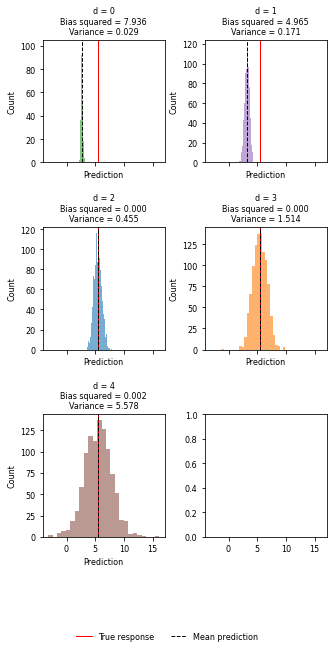

In [18]:
n_exp = 1000
n=50

# Rows correspond to degrees; columns correspond to training datasets.
y_hat_test = np.zeros((len(d_arr), n_exp))

for r in range(n_exp):
    # Use the same fresh training set for all degrees in this experiment.
    x_train = np.random.uniform(-x_max, x_max, n)
    y_train = f(x_train) + np.random.normal(0, sigma_epsilon, n)

    for k in range(len(d_arr)):
        d = d_arr[k]
        w = np.polyfit(x_train, y_train, d)
        y_hat_test[k, r] = np.polyval(w, x_test)

# Average across training datasets, separately for each degree.
mean_prediction = np.mean(y_hat_test, axis=1)
variance = np.var(y_hat_test, axis=1)
bias_squared = (mean_prediction - f(x_test))**2

# Show how predictions vary when we change the training data.
fig, axs = plot_panels(3, 2, sharex=True)
for k in range(len(d_arr)):
    ax = axs.flat[k]
    ax.hist(y_hat_test[k], bins=25, color=colors[k], alpha=0.6)
    ax.axvline(f(x_test), color='red', label='True response')
    ax.axvline(mean_prediction[k], color='black', linestyle='--',
               label='Mean prediction')
    ax.set_title(f'd = {d_arr[k]}\nBias squared = {bias_squared[k]:.3f}'
                 f'\nVariance = {variance[k]:.3f}')
    ax.set_xlabel('Prediction')
    ax.set_ylabel('Count')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()


## Interpret the results

Low-degree polynomials can underfit the true function. Their mean prediction may be far from the truth, even if their predictions vary little across training sets.

Our true function is quadratic, so degree 2 can already represent it exactly. With independent zero-mean noise and a full-rank design, least-squares fits of degree 2 or greater have zero population bias, provided the relevant expectations exist. Estimated squared bias can still be positive because we use finitely many experiments.

Extra polynomial terms can increase variance without improving population bias in this example. Extrapolation can make that variability especially large.

Bias and variance do not have to change monotonically in every problem. We will inspect the measured curves rather than assume their shapes.

Smallest expected MSE: degree 2, MSE = 1.456


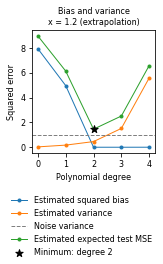

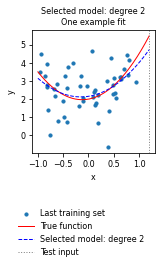

In [19]:
# Combine the three components of expected squared prediction error.
noise_variance = sigma_epsilon**2
expected_test_mse = bias_squared + variance + noise_variance

# Find the model degree with the smallest estimated expected error.
best_index = np.argmin(expected_test_mse)
best_degree = d_arr[best_index]
print(f'Smallest expected MSE: degree {best_degree}, '
      f'MSE = {expected_test_mse[best_index]:.3f}')

fig, ax = plot_panels()
plt.plot(d_arr, bias_squared, 'o-', label='Estimated squared bias')
plt.plot(d_arr, variance, 'o-', label='Estimated variance')
plt.axhline(noise_variance, color='gray', linestyle='--', label='Noise variance')
plt.plot(d_arr, expected_test_mse, 'o-', label='Estimated expected test MSE')
# Mark the minimum of the expected-error curve.
plt.scatter(best_degree, expected_test_mse[best_index],
            color='black', marker='*', s=60, zorder=5,
            label=f'Minimum: degree {best_degree}')
plt.xticks(d_arr)
plt.xlabel('Polynomial degree')
plt.ylabel('Squared error')
plt.title(f'Bias and variance\nx = {x_test} (extrapolation)')
fig.legend(loc='lower center', frameon=False)
plt.show()
# Show one fit of the selected degree using the last training set above.
# The degree was selected by averaging error over all experiments.
best_weights = np.polyfit(x_train, y_train, best_degree)
best_curve = np.polyval(best_weights, x_plot)

fig, ax = plot_panels()
plt.scatter(x_train, y_train, s=10, label='Last training set')
plt.plot(x_plot, f(x_plot), color='red', label='True function')
plt.plot(x_plot, best_curve, 'b--', label=f'Selected model: degree {best_degree}')
plt.axvline(x_test, color='gray', linestyle=':', label='Test input')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Selected model: degree {best_degree}\nOne example fit')
fig.legend(loc='lower center', frameon=False)
plt.show()


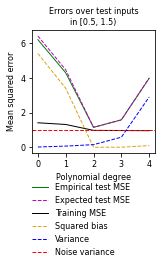

In [17]:
# Average over the original test interval, including extrapolation.
np.random.seed(1)      # Make this final experiment repeatable on its own.

# Use the same quadratic as in the first part of the notebook.
f_final = f

f_model = f_final      # In the assignment, change this to f_assignment.
d_arr = [0, 1, 2, 3, 4]
N = 10000             # Number of observations in the original data pool.
x_max = 1
sigma_epsilon = 1     # Noise standard deviation for this experiment; variance is 1.
n = 100               # Training observations per experiment.
n_exp = 1000
n_test = 100

# Generate the original fixed pool, with training inputs in [-1, 1].
x_pool = np.random.uniform(-x_max, x_max, N)
y_pool = f_model(x_pool) + np.random.normal(0, sigma_epsilon, N)

# Test inputs lie in [0.5, 1.5), so some require extrapolation.
x_test_grid = x_max + np.random.rand(n_test) - 0.5
y_true_grid = f_model(x_test_grid)
y_test_grid = y_true_grid + np.random.normal(0, sigma_epsilon, n_test)

# Sample each training set once, then reuse it for every degree.
train_indices = []
for r in range(n_exp):
    train_indices.append(np.random.permutation(N)[:n])

# Store one summary value per polynomial degree.
train_mse = np.zeros(len(d_arr))
test_mse = np.zeros(len(d_arr))
grid_bias_squared = np.zeros(len(d_arr))
grid_variance = np.zeros(len(d_arr))

for k in range(len(d_arr)):
    d = d_arr[k]

    # Rows are experiments; columns are test inputs, for this degree only.
    predictions = np.zeros((n_exp, n_test))
    training_errors = np.zeros(n_exp)

    for r in range(n_exp):
        # Select the same subsample for all degrees in this experiment.
        idx = train_indices[r]
        x_train = x_pool[idx]
        y_train = y_pool[idx]
        w = np.polyfit(x_train, y_train, d)

        # Measure training error and save predictions at all test inputs.
        fitted_train = np.polyval(w, x_train)
        training_errors[r] = np.mean((y_train - fitted_train)**2)
        predictions[r] = np.polyval(w, x_test_grid)

    # Average predictions over experiments at each test input.
    mean_curve = np.mean(predictions, axis=0)
    variance_curve = np.var(predictions, axis=0)

    # Average the pointwise quantities over the original test inputs.
    train_mse[k] = np.mean(training_errors)
    test_mse[k] = np.mean((predictions - y_test_grid)**2)
    grid_bias_squared[k] = np.mean((mean_curve - y_true_grid)**2)
    grid_variance[k] = np.mean(variance_curve)

# Expected error over new test noise, conditional on this data pool.
# The empirical error on our fixed noisy test set can differ.
grid_expected_mse = grid_bias_squared + grid_variance + sigma_epsilon**2

# Compare empirical and expected test error with the error components.
fig, ax = plot_panels()
plt.plot(d_arr, test_mse, color='green', label='Empirical test MSE')
# Expected test error is squared bias + variance + noise variance.
plt.plot(d_arr, grid_expected_mse, 'm--', label='Expected test MSE')
plt.plot(d_arr, train_mse, color='black', label='Training MSE')
plt.plot(d_arr, grid_bias_squared, '--', color='goldenrod', label='Squared bias')
plt.plot(d_arr, grid_variance, 'b--', label='Variance')
plt.axhline(sigma_epsilon**2, color='red', linestyle='--', label='Noise variance')
plt.xticks(d_arr)
plt.xlabel('Polynomial degree')
plt.ylabel('Mean squared error')
plt.title('Errors over test inputs\nin [0.5, 1.5)')
fig.legend(loc='lower center', frameon=False)
plt.show()

## Assignment: a non-polynomial true function

Use the new function
$$
g(x)=0.5x+\sqrt{\max(x,0)}-\cos(x)+2.
$$

1. Run the next cell to define `f_assignment`. Plot it over $[-1,1]$ and describe its shape.
2. Before fitting models, predict how the bias might differ from the quadratic example, due to the different features of the function $g$ and of the polynomial functions used to model it.
3. In the previous code cell, change `f_model = f_final` to `f_model = f_assignment` and rerun that cell. Keep the sample size, noise level, test interval, and degrees unchanged. Compare the results with the quadratic example.
4. Increase the training sample size from `n = 100` to `n = 500`, rerun that experiment, and explain the changes in squared bias, variance, and test error. Which polynomial degrees $\hat d_{n=100}$ and $\hat d_{n=500}$ provide the best fit in the two cases?
5. For the two cases $\hat d_{n=100}$ and $\hat d_{n=500}$, fit each polynomial to the corresponding training set, and then plot it against the true function $g(x)$.


There is no requirement that the curves be monotonic or that the smallest empirical error identify a unique best degree. Explain the results you observe.

If we use error curves to select a degree, the data used for that choice act as **validation data**. We would need an independent final test set to assess the chosen model's performance.


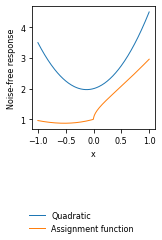

In [59]:
# Define the assignment function separately from the original quadratic.
def f_assignment(x):
    # Clip negative inputs to zero before taking the square root.
    positive_x = np.maximum(x, 0)
    return 0.5 * x + np.sqrt(positive_x) - np.cos(x) + 2

# Compare the two true functions before fitting any models.
x_assignment = np.linspace(-x_max, x_max, 200)
fig, ax = plot_panels()
plt.plot(x_assignment, f_final(x_assignment), label='Quadratic')
plt.plot(x_assignment, f_assignment(x_assignment), label='Assignment function')
plt.xlabel('x')
plt.ylabel('Noise-free response')
fig.legend(loc='lower center', frameon=False)
plt.show()

# Next: change f_model = f_final to f_model = f_assignment in Cell 9 and rerun it.